# Project 2

Alexander Matteson

GitHub link: https://github.com/AlexanderMatteson/Project2_ee513_Matteson

In [6]:
# imports:
import glob, os
import numpy as np
import rawpy
import matplotlib.pyplot as plt

### part A: the classical pipeline


1. Black level subtraction:

In [3]:
folder = r"C:\Users\mattesoa\Documents\Project2_ee513_Matteson\DarkFields"
files = sorted(set(glob.glob(os.path.join(folder, "*.dng")) + glob.glob(os.path.join(folder, "*.DNG"))))
assert len(files) > 0, "No .dng files found"
print(f"Found {len(files)} files")

def channel_planes(raw):
    """Return ({name: 2D array}, {name: manufacturer black}) for each CFA channel."""
    img = raw.raw_image_visible.astype(np.float64)
    pat = raw.raw_pattern
    desc = raw.color_desc.decode()
    bl = raw.black_level_per_channel
    planes, mfr = {}, {}
    g_seen = 0
    for y in range(2):
        for x in range(2):
            idx = pat[y, x]
            name = desc[idx]
            if name == "G":
                g_seen += 1
                name = f"G{g_seen}"
            planes[name] = img[y::2, x::2]
            mfr[name] = bl[idx]
    return planes, mfr

# ---- Load frames ----
frames, mfr_black, white = [], [], []
for f in files:
    with rawpy.imread(f) as raw:
        planes, mfr = channel_planes(raw)
        frames.append(planes)
        mfr_black.append(mfr)
        white.append(raw.white_level)
        print(f"{os.path.basename(f)}: shape={raw.raw_image_visible.shape}, "
              f"pattern={raw.color_desc.decode()}, white_level={raw.white_level}, "
              f"manufacturer black per channel={list(raw.black_level_per_channel)}")

channels = list(frames[0].keys())

# ---- Per-frame stats ----
print("\n=== Per-frame results ===")
for i, f in enumerate(files):
    print(os.path.basename(f))
    for c in channels:
        v = frames[i][c]
        print(f"  {c:>2}: mean={v.mean():9.3f}  median={np.median(v):9.3f}  std={v.std():7.3f}")

# ---- Pooled stats vs manufacturer ----
print("\n=== Pooled across all frames ===")
print(f"{'ch':>3} {'mean':>10} {'median':>10} {'std':>8} {'manufacturer':>13} {'diff(mean-mfr)':>15}")
for c in channels:
    v = np.concatenate([fr[c].ravel() for fr in frames])
    mfr = np.mean([m[c] for m in mfr_black])
    print(f"{c:>3} {v.mean():10.3f} {np.median(v):10.3f} {v.std():8.3f} {mfr:13.3f} {v.mean()-mfr:15.3f}")

if len(set(white)) == 1:
    print(f"\nWhite level (manufacturer): {white[0]}")

Found 3 files
RawCam-2026-11-11-164841.dng: shape=(3024, 4032), pattern=RGBG, white_level=4095, manufacturer black per channel=[528, 528, 528, 528]
RawCam-2026-11-11-164919.dng: shape=(3024, 4032), pattern=RGBG, white_level=4095, manufacturer black per channel=[528, 528, 528, 528]
RawCam-2026-11-11-165101.dng: shape=(3024, 4032), pattern=RGBG, white_level=4095, manufacturer black per channel=[528, 528, 528, 528]

=== Per-frame results ===
RawCam-2026-11-11-164841.dng
   R: mean=  527.909  median=  528.000  std=  6.801
  G1: mean=  528.005  median=  528.000  std=  6.001
  G2: mean=  528.005  median=  528.000  std=  5.373
   B: mean=  527.796  median=  528.000  std=  6.458
RawCam-2026-11-11-164919.dng
   R: mean=  527.777  median=  528.000  std=  6.772
  G1: mean=  527.815  median=  528.000  std=  5.958
  G2: mean=  527.816  median=  528.000  std=  5.334
   B: mean=  527.724  median=  528.000  std=  6.453
RawCam-2026-11-11-165101.dng
   R: mean=  527.952  median=  528.000  std=  6.782
  

In [4]:
blackR = 527.879
blackG = 528.015  # both G1 and G2 had the same values
blackB = 527.779
b_list = [blackR, blackG, blackB]

def subtrackBlackLevel(img, b_list, pattern="RGGB", clip=False):
    """
    Subtract the per-channel black level from a Bayer mosaic.

    img     : 2D raw mosaic array (H x W)
    b_list  : [blackR, blackG, blackB]
    pattern : 2x2 CFA layout read row by row, top-left first,
              e.g. "RGGB", "BGGR", "GRBG", "GBRG"
    clip    : if True, clamp negatives to 0 after subtraction.
              Default False keeps signed values, which preserves
              noise statistics in the shadows.
    Returns a float32 mosaic of the same shape.
    """
    levels = {"R": b_list[0], "G": b_list[1], "B": b_list[2]}
    out = img.astype(np.float32)  # avoid uint16 wraparound

    # positions in the 2x2 tile: (row offset, col offset)
    positions = [(0, 0), (0, 1), (1, 0), (1, 1)]
    for (y, x), ch in zip(positions, pattern.upper()):
        out[y::2, x::2] -= levels[ch]

    if clip:
        np.maximum(out, 0, out=out)
    return out

2. Lens Shading:

In [8]:
# Plane offsets (row, col) inside each 2x2 RGGB cell
RGGB_OFFSETS = {"R": (0, 0), "G1": (0, 1), "G2": (1, 0), "B": (1, 1)}
PLANE_COLORS = {"R": "tab:red", "G1": "tab:green", "G2": "olive", "B": "tab:blue"}


# ----------------------------------------------------------------------------
# 1. Loading
# ----------------------------------------------------------------------------
def load_dng_mosaic(path):
    import rawpy
    with rawpy.imread(path) as raw:
        mosaic = raw.raw_image_visible.copy()
        desc = raw.color_desc.decode()
        idx = raw.raw_pattern.flatten()                 # color index at each 2x2 position
        pattern = "".join(desc[i] for i in idx)
        bl = np.array(raw.black_level_per_channel, dtype=np.float64)
        black = bl[idx]                                 # reorder to 2x2 raster order
        white = float(raw.white_level)
    return {"mosaic": mosaic, "pattern": pattern, "black": black, "white": white}

# ----------------------------------------------------------------------------
# 2. Pattern check
# ----------------------------------------------------------------------------
def check_rggb(pattern):
    ok = pattern == "RGGB"
    print(f"CFA pattern: {pattern}  ->  {'OK (RGGB)' if ok else 'NOT RGGB'}")
    if not ok:
        raise ValueError(
            f"Expected RGGB but got {pattern}. Crop/shift the mosaic or remap offsets "
            "before continuing (an odd crop offset changes the pattern)."
        )
    return ok


def split_planes(mosaic):
    return {k: mosaic[r::2, c::2] for k, (r, c) in RGGB_OFFSETS.items()}


# ----------------------------------------------------------------------------
# 3. Clipping check
# ----------------------------------------------------------------------------
def clipping_report(mosaic, white, tol=0):
    """Fraction of pixels at/near saturation, plus max & percentile per channel."""
    print(f"White level: {white:.0f}   (data max overall: {mosaic.max()})")
    out = {}
    for k, p in split_planes(mosaic).items():
        frac = float(np.mean(p >= white - tol))
        out[k] = dict(max=int(p.max()), p99_9=float(np.percentile(p, 99.9)),
                      frac_clipped=frac)
        flag = "  <-- CLIPPING" if frac > 1e-4 else ""
        print(f"  {k:>2}: max={p.max():6d}  p99.9={out[k]['p99_9']:8.1f}  "
              f"clipped={100*frac:.4f}%{flag}")
    return out


# ----------------------------------------------------------------------------
# 4. Horizontal profile plot
# ----------------------------------------------------------------------------
def plot_horizontal_profiles(mosaic, black, save_path=None, title="Flat field horizontal profile"):
    import matplotlib.pyplot as plt

    planes = split_planes(mosaic.astype(np.float64))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for i, (k, p) in enumerate(planes.items()):
        row = p[p.shape[0] // 2, :] - black[i]
        x = np.arange(row.size) * 2
        axes[0].plot(x, row, color=PLANE_COLORS[k], label=k, lw=0.9)
        axes[1].plot(x, row / np.median(row[row.size // 2 - 25: row.size // 2 + 25]),
                     color=PLANE_COLORS[k], label=k, lw=0.9)
    axes[0].set(title="Black-subtracted (DN)", xlabel="x (mosaic pixel)", ylabel="DN")
    axes[1].set(title="Normalized to center", xlabel="x (mosaic pixel)", ylabel="relative")
    for a in axes:
        a.grid(alpha=0.3); a.legend()
    fig.suptitle(title)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150)
    return fig


# ----------------------------------------------------------------------------
# 5. Gain map from flat field
# ----------------------------------------------------------------------------
def build_gain_map(flat_mosaic, black, center_frac=0.05, smooth_sigma=8.0,
                   max_gain=8.0):
    """
    Per-plane (R, G1, G2, B) gain map, same shape as the mosaic.

    For each plane:  flat = plane - black   (linear light, black removed)
                     flat = optional gaussian smoothing (suppresses noise)
                     gain = center / flat,  center = median of central patch
    Returns float32 array HxW (gain at each mosaic site).
    """
    H, W = flat_mosaic.shape
    gain = np.ones((H, W), dtype=np.float32)
    planes = split_planes(flat_mosaic.astype(np.float64))

    for i, (k, (r, c)) in enumerate(RGGB_OFFSETS.items()):
        p = planes[k] - black[i]
        p = np.clip(p, 1.0, None)                      # avoid divide by <=0
        if smooth_sigma and smooth_sigma > 0:
            from scipy.ndimage import gaussian_filter
            p = gaussian_filter(p, smooth_sigma, mode="nearest")
        h, w = p.shape
        ch, cw = max(int(h * center_frac), 4), max(int(w * center_frac), 4)
        center = np.median(p[h // 2 - ch: h // 2 + ch, w // 2 - cw: w // 2 + cw])
        g = np.clip(center / p, None, max_gain)
        gain[r::2, c::2] = g.astype(np.float32)
    return gain


# ----------------------------------------------------------------------------
# 6. Apply
# ----------------------------------------------------------------------------
def apply_lens_shading(mosaic, gain, black, white=None, keep_black_level=False):
    """
    corrected = (mosaic - black) * gain   (float32, linear, black-subtracted)
    If keep_black_level, black is added back so downstream steps see raw-like DN.
    """
    if gain.shape != mosaic.shape:
        import cv2
        gain = cv2.resize(gain, (mosaic.shape[1], mosaic.shape[0]),
                          interpolation=cv2.INTER_LINEAR)
    out = np.empty(mosaic.shape, dtype=np.float32)
    m = mosaic.astype(np.float32)
    for i, (k, (r, c)) in enumerate(RGGB_OFFSETS.items()):
        out[r::2, c::2] = np.clip(m[r::2, c::2] - black[i], 0, None)
    out *= gain
    if white is not None:
        out = np.clip(out, 0, white - float(np.mean(black)))
    if keep_black_level:
        for i, (k, (r, c)) in enumerate(RGGB_OFFSETS.items()):
            out[r::2, c::2] += black[i]
    return out


# ----------------------------------------------------------------------------
# Reusable entry point: calibrate once, correct many images
# ----------------------------------------------------------------------------
def calibrate_from_flat(flat_dng_path, gain_out="lsc_gain.npz", **kw):
    d = load_dng_mosaic(flat_dng_path)
    check_rggb(d["pattern"])
    np.savez(gain_out, gain=build_gain_map(d["mosaic"], d["black"], **kw),
             black=d["black"], white=d["white"])
    return gain_out


def correct_lens_shading(image, gain_npz="lsc_gain.npz", keep_black_level=False):
    """
    image: path to a DNG, OR a dict from load_dng_mosaic, OR a raw mosaic ndarray.
    Returns float32 linear mosaic (black-subtracted unless keep_black_level).
    """
    cal = np.load(gain_npz)
    gain, cal_black, white = cal["gain"], cal["black"], float(cal["white"])
    if isinstance(image, str):
        image = load_dng_mosaic(image)
    if isinstance(image, dict):
        check_rggb(image["pattern"])
        mosaic, black = image["mosaic"], image["black"]
    else:
        mosaic, black = image, cal_black      # bare array: assume same sensor settings
    return apply_lens_shading(mosaic, gain, black, white, keep_black_level)

Mosaic shape: (3024, 4032) | black (R,G1,G2,B): [528. 528. 528. 528.] | white: 4095.0
CFA pattern: RGGB  ->  OK (RGGB)
White level: 4095   (data max overall: 2064)
   R: max=  1715  p99.9=  1540.0  clipped=0.0000%
  G1: max=  2064  p99.9=  1881.0  clipped=0.0000%
  G2: max=  2045  p99.9=  1873.0  clipped=0.0000%
   B: max=  1061  p99.9=   987.0  clipped=0.0000%


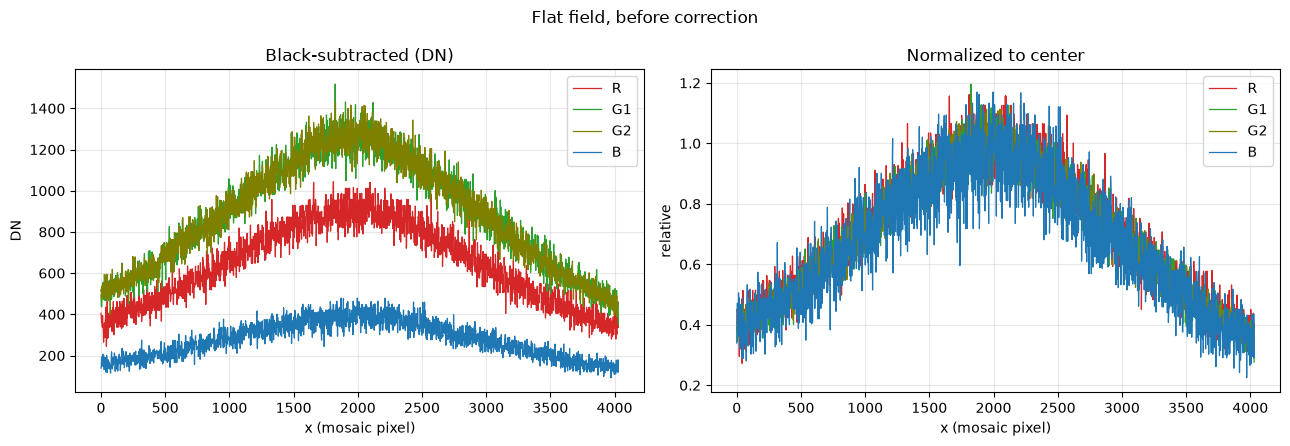

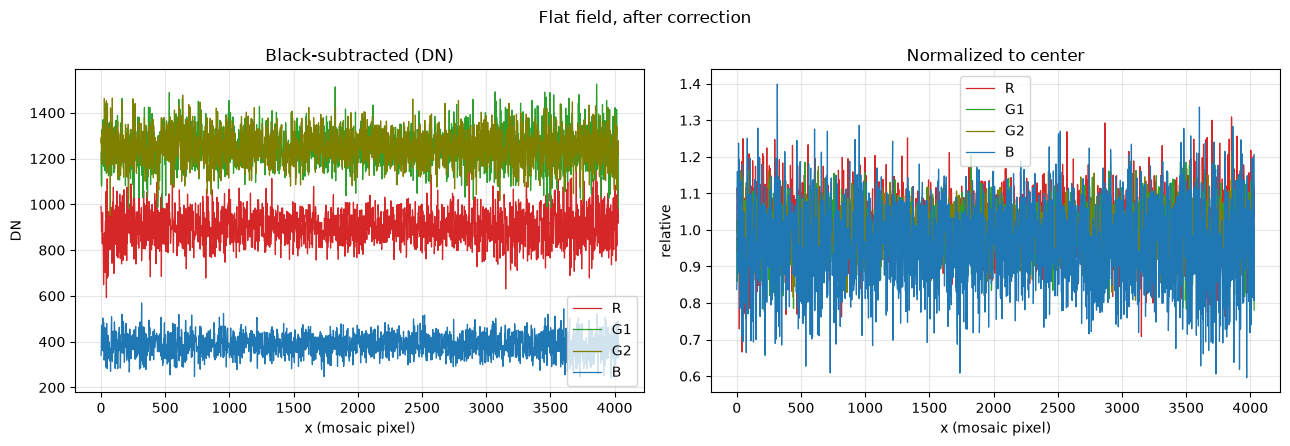

In [9]:
%matplotlib inline

flat_path = r"C:\Users\mattesoa\Documents\Project2_ee513_Matteson\ColorCorrection\Set2\IMG_0358.DNG"

# 1. Load
d = load_dng_mosaic(flat_path)
print("Mosaic shape:", d["mosaic"].shape, "| black (R,G1,G2,B):", d["black"], "| white:", d["white"])

# 2. RGGB check
check_rggb(d["pattern"])

# 3. Clipping per channel
clipping_report(d["mosaic"], d["white"])

# 4. Horizontal profiles (before correction)
plot_horizontal_profiles(d["mosaic"], d["black"], title="Flat field, before correction")
plt.show()

# 5. Build the per-channel gain map and apply it to the flat itself
gain = build_gain_map(d["mosaic"], d["black"])
corrected = apply_lens_shading(d["mosaic"], gain, d["black"], d["white"], keep_black_level=True)

# 6. Profiles after correction. The flat should now be flat for every channel.
plot_horizontal_profiles(corrected, d["black"], title="Flat field, after correction")
plt.show()

# 7. Save the calibration so you can reuse it on your scene captures
np.savez("lsc_gain.npz", gain=gain, black=d["black"], white=d["white"])

In [ ]:
# apply to image we are processing:
scene_path = r"C:\Users\mattesoa\Documents\Project2_ee513_Matteson\...\IMG_xxxx.DNG"
mosaic_lsc = correct_lens_shading(scene_path, "lsc_gain.npz")   # linear, black-subtracted float32 mosaic

3. Defective pixel map: